In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

df.describe()

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


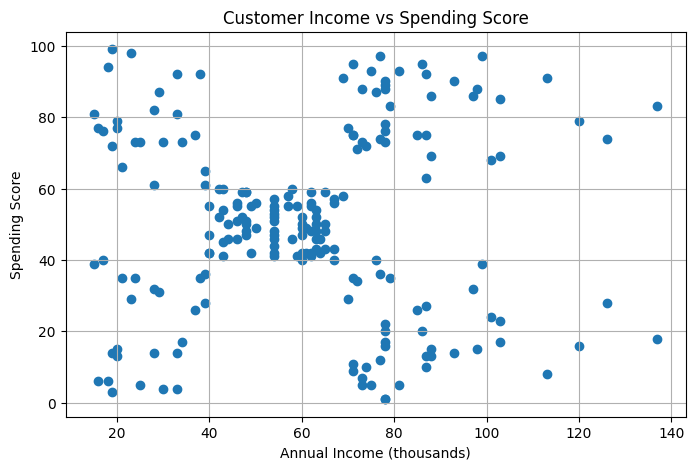

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)

plt.title("Customer Income vs Spending Score")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.grid(True)
plt.show()

In [5]:
from sklearn.preprocessing import StandardScaler

# Select the features for clustering
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared successfully!")
print("Number of customers:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Data prepared successfully!
Number of customers: 200
Number of features: 2


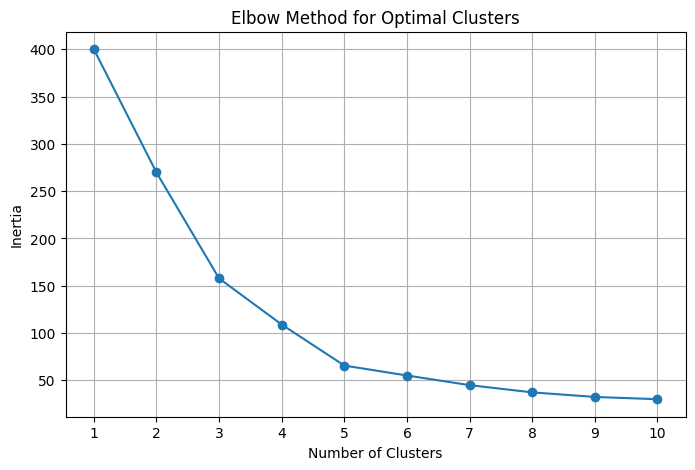

In [6]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [7]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer segmentation completed!")
print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head(10))

print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Customer segmentation completed!
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


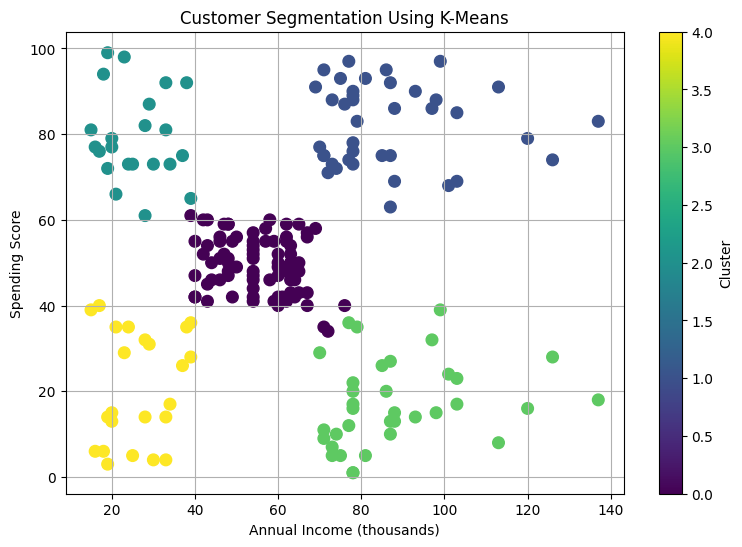

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=70
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [9]:
cluster_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("Cluster", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print(cluster_summary)

         Number_of_Customers  Average_Age  Average_Annual_Income  \
Cluster                                                            
0                         81        42.72                  55.30   
1                         39        32.69                  86.54   
2                         22        25.27                  25.73   
3                         35        41.11                  88.20   
4                         23        45.22                  26.30   

         Average_Spending_Score  
Cluster                          
0                         49.52  
1                         82.13  
2                         79.36  
3                         17.11  
4                         20.91  


In [10]:
df.to_csv("Customer_Segmentation_Results.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [11]:
from google.colab import files

files.download("Customer_Segmentation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Calculate average values for each customer segment
summary = df.groupby("Cluster").agg(
    Customers=("Cluster", "count"),
    Age=("Age", "mean"),
    Income=("Annual Income (k$)", "mean"),
    Spending=("Spending Score (1-100)", "mean")
).round(2)

# Give each segment a simple business label
def label_segment(row):
    if row["Income"] >= df["Annual Income (k$)"].median() and row["Spending"] >= df["Spending Score (1-100)"].median():
        return "High Income - High Spending"
    elif row["Income"] >= df["Annual Income (k$)"].median() and row["Spending"] < df["Spending Score (1-100)"].median():
        return "High Income - Low Spending"
    elif row["Income"] < df["Annual Income (k$)"].median() and row["Spending"] >= df["Spending Score (1-100)"].median():
        return "Low Income - High Spending"
    else:
        return "Low Income - Low Spending"

summary["Segment"] = summary.apply(label_segment, axis=1)

print(summary)

         Customers    Age  Income  Spending                      Segment
Cluster                                                                 
0               81  42.72   55.30     49.52    Low Income - Low Spending
1               39  32.69   86.54     82.13  High Income - High Spending
2               22  25.27   25.73     79.36   Low Income - High Spending
3               35  41.11   88.20     17.11   High Income - Low Spending
4               23  45.22   26.30     20.91    Low Income - Low Spending


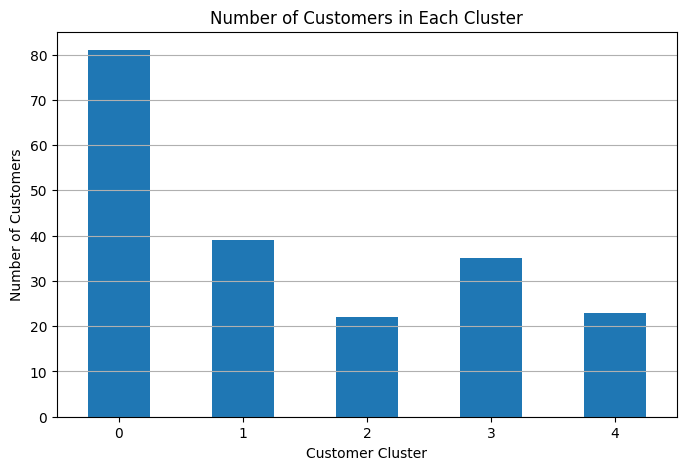

In [13]:
plt.figure(figsize=(8, 5))

df["Cluster"].value_counts().sort_index().plot(kind="bar")

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

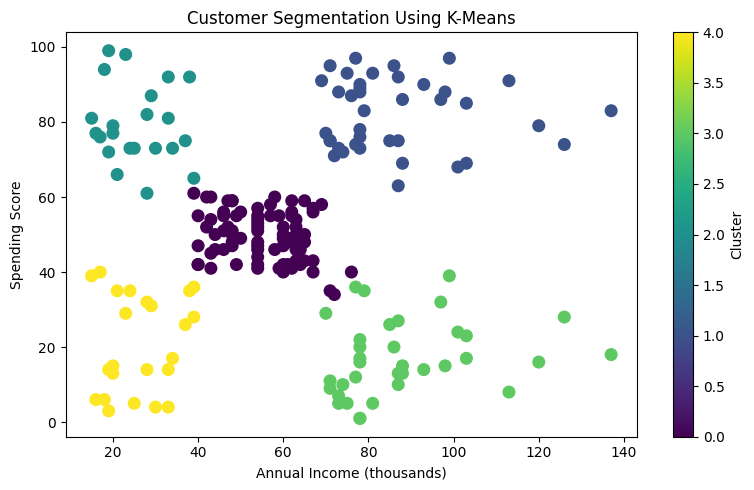

Summary and chart saved successfully!


In [14]:
summary.to_csv("Customer_Segment_Summary.csv")

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=70
)
plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.savefig("Customer_Segmentation_Chart.png", dpi=300)
plt.show()

print("Summary and chart saved successfully!")

In [15]:
from google.colab import files

files.download("Customer_Segment_Summary.csv")
files.download("Customer_Segmentation_Chart.png")
files.download("Customer_Segmentation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Customer Segmentation Using K-Means Clustering

## 1. Introduction
Customer segmentation is the process of dividing customers into groups based on similar characteristics or behavior. It helps businesses understand different customer types and plan suitable marketing strategies.

## 2. Objective
The objective of this project is to group mall customers using their annual income and spending scores.

## 3. Dataset
The Mall Customer Segmentation dataset contains customer information, including gender, age, annual income, and spending score.

## 4. Tools and Technologies
- Python
- Google Colab
- Pandas
- Matplotlib
- Scikit-learn
- K-Means Clustering

## 5. Methodology
1. Loaded the dataset.
2. Checked the data and missing values.
3. Visualized customer income and spending scores.
4. Standardized the selected features.
5. Used the Elbow Method to help choose the number of clusters.
6. Applied K-Means clustering.
7. Visualized and summarized the resulting customer groups.

## 6. Results
The K-Means algorithm divided customers into five groups. The groups can be examined using their average income and spending scores to identify different customer patterns.

Add your actual cluster summary and chart here.

## 7. Conclusion
Customer segmentation helps businesses understand differences in customer behavior. The resulting groups can support targeted promotions and better marketing decisions.

## 8. Limitation
The dataset is small and uses spending scores assigned to mall customers rather than detailed transaction histories. The results may not represent all customers or businesses.
